In [1]:
from IPython.display import Image, display_png
from sympy import *
from sympy.physics.quantum import *
from sympy.physics.quantum.qubit import Qubit,QubitBra
init_printing() # ベクトルや行列を綺麗に表示するため

In [2]:
psi = Qubit('0')
psi

In [3]:
represent(psi) #列ベクトル表示


⎡1⎤
⎢ ⎥
⎣0⎦

In [4]:
a, b = symbols('alpha, beta')  #a, bをシンボルとして、alpha, betaとして表示
ket0 = Qubit('0')
ket1 = Qubit('1')
psi = a * ket0 + b* ket1
psi # 状態をそのまま書くとケットで表示してくれる

In [5]:
from sympy.physics.quantum.gate import X, Y, Z, H, S, T, CNOT, SWAP, CPHASE, CGate

In [6]:
X(0)
represent(X(0), nqubits=1) # 泡利 X

⎡0  1⎤
⎢    ⎥
⎣1  0⎦

In [7]:
represent(H(0), nqubits=1)

⎡1    1  ⎤
⎢──   ── ⎥
⎢√2   √2 ⎥
⎢        ⎥
⎢1   -√2 ⎥
⎢──  ────⎥
⎣√2   2  ⎦

In [8]:
represent(S(0), nqubits=1) # Sは位相シフトゲートで、|1>の位相をiに変える

⎡1  0⎤
⎢    ⎥
⎣0  ⅈ⎦

In [9]:
represent(T(0), nqubits=1) # Tは位相シフトゲートで、|1>の位相をexp(i*pi/4)に変える

⎡1   0  ⎤
⎢       ⎥
⎢    ⅈ⋅π⎥
⎢    ───⎥
⎢     4 ⎥
⎣0  ℯ   ⎦

In [10]:
# from sympy.physics.quantum.circuitplot import circuit_plot
# # 创建一个包含 H 门、X 门和 CNOT 门的电路
# # nqubits=2 表示该电路共有 2 个量子比特
# c = CNOT(1,0) * X(0) * H(1)
# circuit_plot(c, nqubits=2)

量子线路的深度为: 3


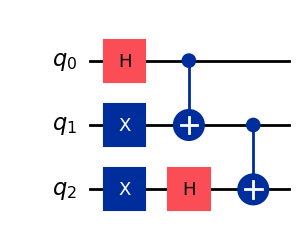

In [ ]:
from qiskit import QuantumCircuit
from qiskit.converters import circuit_to_dag, dag_to_circuit

def auto_add_barriers(circuit: QuantumCircuit) -> QuantumCircuit:
    """自动在量子线路的每一个物理层（Layer）之间插入 barrier"""
    dag = circuit_to_dag(circuit)
    new_circuit = QuantumCircuit(*circuit.qregs, *circuit.cregs)
    
    # 遍历 DAG 的每一层
    for layer in dag.layers():
        # 将当前层中的所有门加入新线路
        for node in layer['graph'].op_nodes():
            new_circuit.append(node.op, node.qargs, node.cargs)
        # 在每层结束时自动切一刀（如果是最后一层则不加，保持美观）
        new_circuit.barrier()
        
    return new_circuit

# ==================== 测试线路 ====================
qc = QuantumCircuit(3)
qc.h(0)
qc.x(1)       
qc.cx(0, 1)
qc.x(2)
qc.h(2)   
qc.cx(1, 2)   

# 自动化
qc_segmented = auto_add_barriers(qc)

circuit_depth = qc.depth()
print(f"量子线路的深度为: {circuit_depth}")

# 打印
qc.draw(output='mpl', fold=-1, style='iqp')

In [19]:
total_gates = qc.size()
print(f"线路中的总门数为: {total_gates}")

线路中的总门数为: 6
